In [1]:
import pandas as pd

# 1. Carregando os dados brutos do arquivo correto
caminho_arquivo = '../data/raw/MatchStatsTbl.csv'
df_completo = pd.read_csv(caminho_arquivo)

# 2. Exibindo o tamanho original do dataset
print(f"Total de linhas originais: {df_completo.shape[0]}")

# 3. Filtrando apenas os Top Laners (tratando maiúsculas/minúsculas por segurança)
df_top = df_completo[df_completo['Lane'].astype(str).str.upper() == 'TOP'].copy()

# 4. Verificando o novo tamanho do dataset filtrado
print(f"\nTotal de linhas (Apenas Top Laners): {df_top.shape[0]}")

# 5. Exibindo apenas as colunas que farão parte da nossa Regressão Linear
colunas_modelo = ['TotalGold', 'MinionsKilled', 'DmgDealt', 'Win']
print("\nAmostra dos dados prontos para a análise exploratória:")
display(df_top[colunas_modelo].head())

Total de linhas originais: 732308

Total de linhas (Apenas Top Laners): 104169

Amostra dos dados prontos para a análise exploratória:


,TotalGold,MinionsKilled,DmgDealt,Win
4,15012,0,39106,1
5,12000,0,30259,1
9,18209,42,51900,1
11,15387,34,33814,1
15,18346,138,43823,1


Linhas válidas após remover AFKs: 103860



,TotalGold,MinionsKilled,DmgDealt
TotalGold,1.000000,0.252117,0.802914
MinionsKilled,0.252117,1.000000,0.068589
DmgDealt,0.802914,0.068589,1.000000


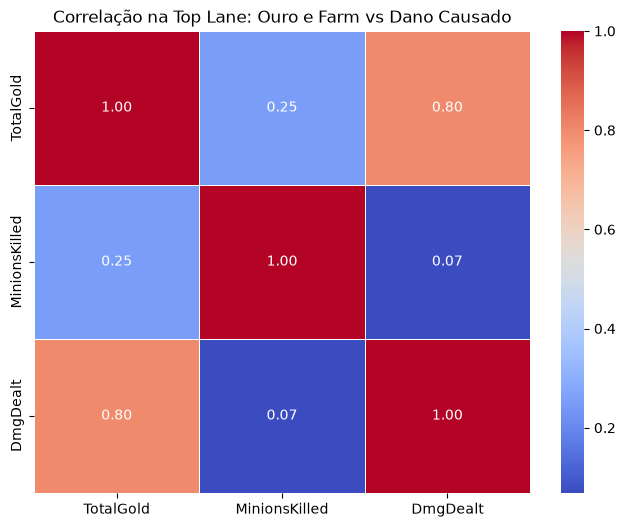

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Limpeza de Anomalias: Remover partidas onde o jogador ficou AFK (Dano ou Ouro zerados)
df_limpo = df_top.dropna(subset=['TotalGold', 'MinionsKilled', 'DmgDealt'])
df_limpo = df_limpo[(df_limpo['TotalGold'] > 0) & (df_limpo['DmgDealt'] > 0)]

print(f"Linhas válidas após remover AFKs: {df_limpo.shape[0]}\n")

# 2. Matriz de Correlação (A prova matemática)
colunas_analise = ['TotalGold', 'MinionsKilled', 'DmgDealt']
matriz_correlacao = df_limpo[colunas_analise].corr()

display(matriz_correlacao)

# 3. Gerando o Gráfico (Excelente para o README do GitHub)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacao, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlação na Top Lane: Ouro e Farm vs Dano Causado')
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Separando a feature (X = Ouro Total) e o alvo (y = Dano Causado)
X = df_limpo[['TotalGold']]
y = df_limpo['DmgDealt']

# 2. Dividindo o dataset: 80% para o algoritmo aprender, 20% para testarmos a prova
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Instanciando e Treinando o Modelo (O "coração" do Machine Learning)
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 4. Usando o modelo treinado para prever os dados da base de teste
y_pred = modelo.predict(X_test)

# 5. Extraindo a inteligência matemática gerada
peso_ouro = modelo.coef_[0]
r_quadrado = r2_score(y_test, y_pred)
erro_medio = mean_absolute_error(y_test, y_pred)

print(f"Coeficiente Angular (Peso do Ouro): {peso_ouro:.2f}")
print(f"-> Cada 1 unidade de Ouro total resulta em {peso_ouro:.2f} de Dano causado.")
print(f"\nR² (Poder de Explicação): {r_quadrado:.2f}")
print(f"Erro Médio Absoluto (MAE): {erro_medio:.2f} de Dano")

Coeficiente Angular (Peso do Ouro): 2.95
-> Cada 1 unidade de Ouro total resulta em 2.95 de Dano causado.

R² (Poder de Explicação): 0.65
Erro Médio Absoluto (MAE): 6662.52 de Dano
